In [ ]:
# PCA + Scree Plot + Biplot
# Next Level Prep | By David H. Nguyen, PhD | Last udpated 7/20/25

# NOTE: You have to write/paste in information  for Step 4, 7, and 10!!!

In [2]:
# Step 1

import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

In [3]:
# Step 2

os.chdir(r'C:\Users\Yusif Alabed\Downloads\')

# For Windows users, put r in front of "path" because Python interprets "\" differently than Windows. r stands for "raw"
#os.chdir(r"C:\path\to\your\directory")

In [5]:
# Step 3

# Read the CSV file
file_path = 'Core Patient Data_Wang_standardized4PCA_standardized4PCAwithouteGFR.csv"'
df = pd.read_csv(r"Core Patient Data_Wang_standardized4PCA_standardized4PCAwithouteGFR.csv")
df

# For Windows users, put r in front of "path" 
# df = pd.read_csv(r"C:\path\to\your\file.csv")

,Sample Name,Gender,ESRD_status,BMI,Urea,Creatinine
0,CON-001-S,female,-1.0,-0.727188,-1.500661,-1.564864
1,CON-002-S,female,-1.0,-0.493516,-1.510625,-1.506008
2,CON-003-S,female,-1.0,0.069167,-1.570405,-1.559555
3,CON-005-S,female,-1.0,-0.424349,-1.580369,-1.573173
4,CON-006-S,female,-1.0,0.085991,-1.560442,-1.550092
...,...,...,...,...,...,...
785,KD-194-Fb,male,0.0,-0.078510,0.717198,1.150375
786,KD-202-Fb,male,0.0,-0.865075,1.020086,0.109426
787,KD-211-Fb,female,0.0,-0.783161,-0.994519,-0.661477
788,KD-214-Fb,female,0.0,-1.151342,-0.276156,-0.299106


In [6]:
# Extract base name without suffix for naming the output files of this script
base_name = os.path.splitext(os.path.basename(file_path))[0]
base_name

'Core Patient Data_Wang_standardized4PCA_standardized4PCAwithouteGFR'

============================================================================================
# Extract sample IDs to later add it to the csv file containing the first 3 PC values of each sample.
# NOTE: Do this ONLY after all data cleaning is done (fixing missing values, removing duplicates, etc.)

In [7]:
# Step 4

# Extract sample names. 
sample_labels = df[['Gender', 'Sample Name', 'ESRD_status']]
sample_labels.head()

,Gender,Sample Name,ESRD_status
0,female,CON-001-S,-1.0
1,female,CON-002-S,-1.0
2,female,CON-003-S,-1.0
3,female,CON-005-S,-1.0
4,female,CON-006-S,-1.0


# Drop non-numerical columns

In [8]:
# Step 5

df_numOnly = df.drop(sample_labels, axis=1)
df_numOnly

,BMI,Urea,Creatinine
0,-0.727188,-1.500661,-1.564864
1,-0.493516,-1.510625,-1.506008
2,0.069167,-1.570405,-1.559555
3,-0.424349,-1.580369,-1.573173
4,0.085991,-1.560442,-1.550092
...,...,...,...
785,-0.078510,0.717198,1.150375
786,-0.865075,1.020086,0.109426
787,-0.783161,-0.994519,-0.661477
788,-1.151342,-0.276156,-0.299106


============================================================================================
# PCA

In [9]:
# Step 6

# Perform PCA with 3 components
pca = PCA()
principal_components = pca.fit_transform(df_numOnly)

# Use only the first 3 components for plotting and saving
# But include the information in the columns contained in sample_labels
pc_df = pd.concat([sample_labels.reset_index(drop=True), 
                   pd.DataFrame(principal_components[:, :3], 
                                columns=["PC1", "PC2", "PC3"])],
                  axis=1)

pc_df.head()

,Gender,Sample Name,ESRD_status,PC1,PC2,PC3
0,female,CON-001-S,-1.0,-2.194754,-0.707871,0.025986
1,female,CON-002-S,-1.0,-2.151695,-0.471956,0.051601
2,female,CON-003-S,-1.0,-2.211383,0.090974,0.000607
3,female,CON-005-S,-1.0,-2.245933,-0.399489,0.046371
4,female,CON-006-S,-1.0,-2.197046,0.107175,-0.001357


# Save the values of the first 3 PCs as a csv file with suffix "_1st3PCvalues.csv"

In [10]:
# Create new output filename
fileName = base_name + "_1st3PCvalues.csv"

# Save the DataFrame
pc_df.to_csv(fileName, index=False)

============================================================================================
# 3D Scatter Plot

# Run the below cell and, in the provided text box, type in the exact name of the column that contains the sample labels.

In [11]:
# Step 7

# User types the column name silently (no prompt)
label_column = input()

# Check if the column exists in the DataFrame
if label_column not in pc_df.columns:
    raise ValueError(f"Column '{label_column}' not found in the DataFrame.")

 ESRD_status


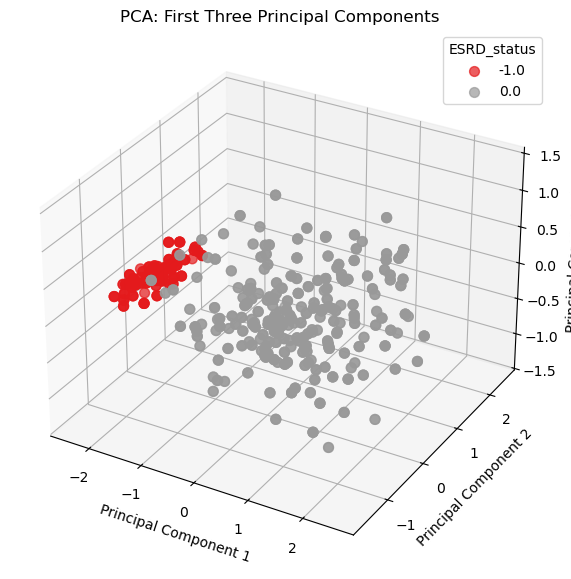

In [12]:
# Step 8

# Unique categories based on user input
categories = pc_df[label_column].unique()

# Updated colormap usage (Matplotlib 3.7+)
colors = plt.colormaps.get_cmap('Set1').resampled(len(categories))

# Create 3D scatter plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Scatter each category separately
for i, category in enumerate(categories):
    subset = pc_df[pc_df[label_column] == category]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        subset["PC3"],
        label=category,
        alpha=0.7,
        s=50,
        color=colors(i)
    )

# Labels and title
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
ax.set_title("PCA: First Three Principal Components")
ax.legend(title=label_column)

plt.show()


============================================================================================
# Scree Plot

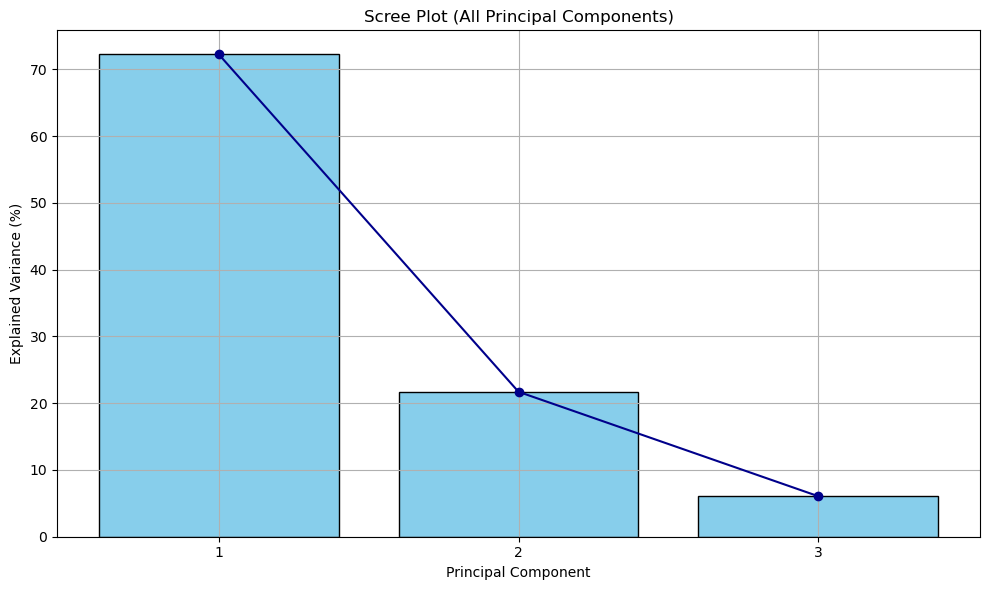

In [13]:
# Step 9

explained_var = pca.explained_variance_ratio_ * 100
num_components = len(explained_var)

plt.figure(figsize=(10, 6))
plt.bar(range(1, num_components + 1), explained_var, color='skyblue', edgecolor='black')
plt.plot(range(1, num_components + 1), explained_var, 'o-', color='darkblue')
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Scree Plot (All Principal Components)")
plt.xticks(range(1, num_components + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

============================================================================================
# PCA Biplot (PC1 vs PC2)

In [15]:
# Step 10

# Ask user to type in the exact name of the column that contains the sample labels
label_column = input()

 ESRD_status


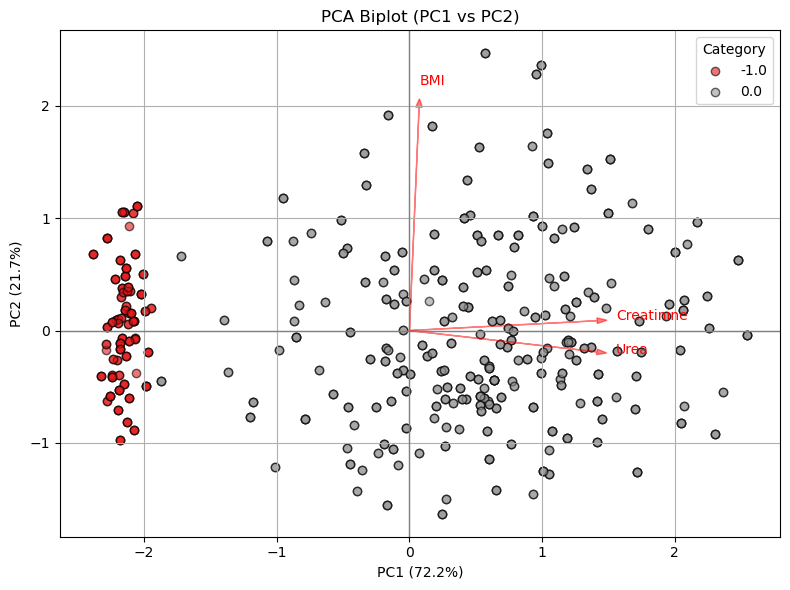

In [16]:
# Step 11

# Check the column exists
if label_column not in pc_df.columns:
    raise ValueError(f"Column '{label_column}' not found in the DataFrame.")

# Extract the actual group values 
groups = pc_df[label_column].values

# Confirm alignment
assert len(groups) == principal_components.shape[0]

# Define biplot
def biplot(score, coeff, labels=None, groups=None):
    xs = score[:, 0]
    ys = score[:, 1]
    plt.figure(figsize=(8, 6))

    if groups is None:
        plt.scatter(xs, ys, alpha=0.6, edgecolor='k')
    else:
        categories = np.unique(groups)
        colors = plt.colormaps.get_cmap('Set1').resampled(len(categories))

        for i, category in enumerate(categories):
            mask = (groups == category)
            plt.scatter(xs[mask], ys[mask], alpha=0.6, edgecolor='k', label=category, color=colors(i))
        plt.legend(title="Category")

    # Arrows for features
    for i in range(coeff.shape[0]):
        plt.arrow(0, 0, coeff[i, 0]*2, coeff[i, 1]*2, color='r', alpha=0.5, head_width=0.05)
        if labels is not None:
            plt.text(coeff[i, 0]*2.2, coeff[i, 1]*2.2, labels[i], color='r')

    plt.xlabel(f"PC1 ({explained_var[0]:.1f}%)")
    plt.ylabel(f"PC2 ({explained_var[1]:.1f}%)")
    plt.title("PCA Biplot (PC1 vs PC2)")
    plt.grid(True)
    plt.axhline(0, color='gray', lw=1)
    plt.axvline(0, color='gray', lw=1)
    plt.tight_layout()
    plt.show()

# Call it
biplot(principal_components, pca.components_.T, labels=df_numOnly.columns, groups=groups)


# Show Arrows (aka Feature Loadings) Only

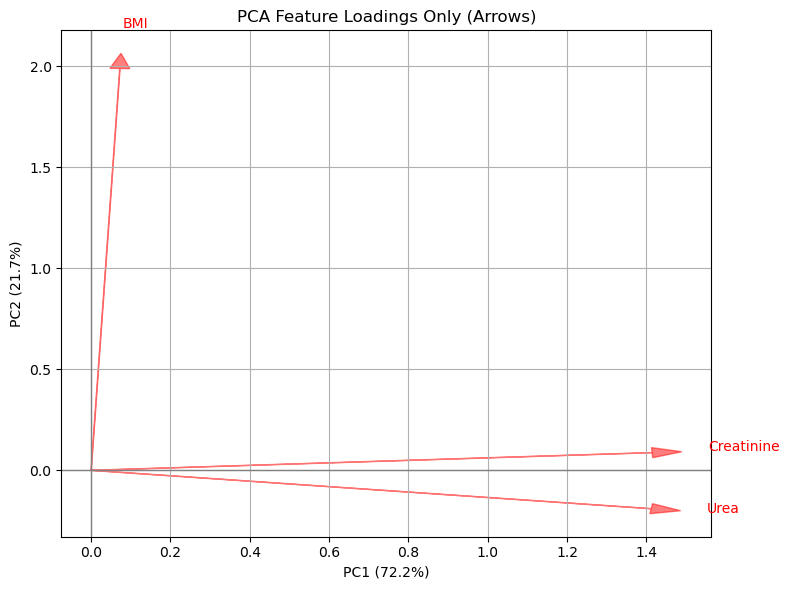

In [17]:
def biplot(score, coeff, labels=None, groups=None):
    plt.figure(figsize=(8, 6))

    # Draw arrows for feature loadings
    for i in range(coeff.shape[0]):
        plt.arrow(0, 0, coeff[i, 0]*2, coeff[i, 1]*2, color='r', alpha=0.5, head_width=0.05)
        if labels is not None:
            plt.text(coeff[i, 0]*2.2, coeff[i, 1]*2.2, labels[i], color='r')

    plt.xlabel(f"PC1 ({explained_var[0]:.1f}%)")
    plt.ylabel(f"PC2 ({explained_var[1]:.1f}%)")
    plt.title("PCA Feature Loadings Only (Arrows)")
    plt.grid(True)
    plt.axhline(0, color='gray', lw=1)
    plt.axvline(0, color='gray', lw=1)
    plt.tight_layout()
    plt.show()

# Call it
biplot(principal_components, pca.components_.T, labels=df_numOnly.columns, groups=groups)